
## 問題 7-1

バスがバス停に２０分毎に到着し、乗客がバス停にランダムに来るとしたら、バスが到着するまでに乗客が待つ時間は、０から２０分の間に一様に分布する。

しかし、実際は、バスの間隔に変動がある。乗客がバスを待っていると仮定し、さらに、バスの過去の時間間隔も知っているとして、待ち時間の分布を計算せよ。

ヒント：バスの間隔が５分か１０分かのどちらかに等しい確率でなっていると仮定しよう。あなたが、１０分間隔のどれかにバス停に着く確率はどれくらいか。

この問題は、**「バスの間隔の分布」と「乗客が実際に遭遇する間隔の分布」は違う**、というところが一番大事です。

今回の答えは、

* バスの間隔：5分、10分がそれぞれ **1/2**
* しかし乗客が遭遇する間隔：

  * 5分間隔 → **1/3**
  * 10分間隔 → **2/3**
* したがって待ち時間の分布は、単純な一様分布ではなく、

  * 0～5分では密度 **2/15 ≈ 0.1333**
  * 5～10分では密度 **1/15 ≈ 0.0667**
* 平均待ち時間は **4.167分**

となります。

### なぜ10分間隔に遭遇しやすいのか

ここを図2で見ると分かりやすいです。

バスの間隔そのものは、

```text
5分間隔   → 50%
10分間隔  → 50%
```

です。

ところが、乗客がランダムな時刻にバス停へ来ると、

```text
5分間隔  ├─────┤
10分間隔 ├──────────┤
```

となって、10分間隔のほうが**乗客が入り込める時間が2倍あります**。

したがって、

$$
P(10分間隔\mid乗客が来た)
=
\frac{10\times0.5}{5\times0.5+10\times0.5}
=\frac{10}{15}
=\frac23
$$

です。

これがヒントの答え、**「10分間隔のどれかにバス停に着く確率は \(2/3\)」**です。

---

### そして待ち時間の分布

10分間隔に遭遇した場合は、待ち時間は

$$
0～10分
$$

に一様分布します。

5分間隔なら、

$$
0～5分
$$

に一様分布します。

したがって全体は、この2つを

$$
\frac13,\quad\frac23
$$

の重みで混ぜたものになります。

特に面白いのは **5分を境に高さが変わる**ことです。

```text
確率密度
  |
.20|  5分間隔だけなら ─────────
  |                         |
.13|  全体 ────────────────┐
  |                         │
.067|                       └────────────
  |                         |
  +--------------------------------------
     0              5              10
                  待ち時間（分）
```

つまり、**「0～10分の一様分布」ではありません。**

5分を超えて待つ人は、必ず10分間隔のバスに遭遇した人ですから、5～10分の部分の密度が低くなります。

=== バスの間隔そのものの確率 ===
5分間隔  : 0.500
10分間隔 : 0.500

=== 乗客が実際に遭遇する確率 ===
5分間隔  : 0.333
10分間隔 : 0.667

=== 待ち時間 ===
平均待ち時間 : 0.833 + 3.333 = 4.167 分


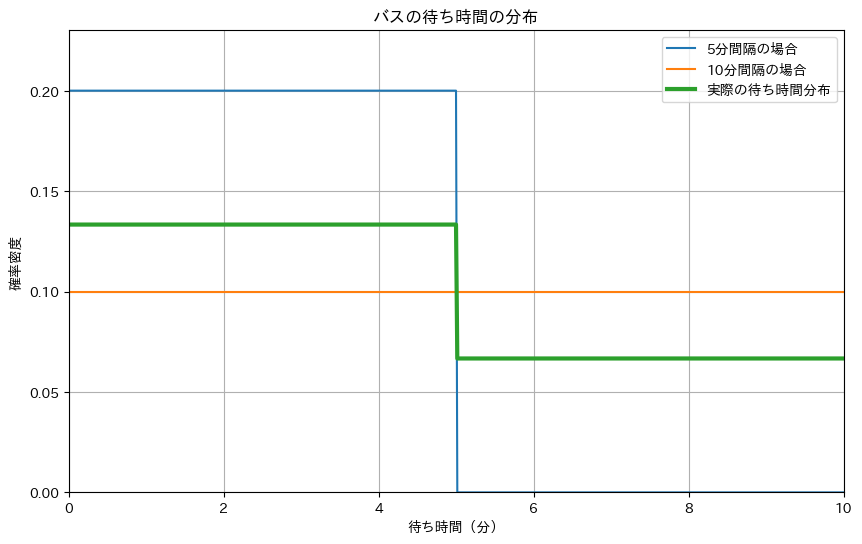

In [208]:
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

# ============================================================
# バスの待ち時間問題
#
# バスの間隔は 5分 または 10分
# それぞれの確率は 1/2
# 乗客はランダムな時刻にバス停に来る
# ============================================================


# ------------------------------------------------------------
# 1. バスの間隔
# ------------------------------------------------------------

interval_5 = 5
interval_10 = 10

# バスの間隔そのものの確率
p_5 = 0.5
p_10 = 0.5


# ------------------------------------------------------------
# 2. 乗客が遭遇する確率を計算する
#
# ランダムな時刻に来るので、
# 「その間隔の長さ」に比例して遭遇しやすい
# ------------------------------------------------------------

weight_5 = interval_5 * p_5
weight_10 = interval_10 * p_10

total_weight = weight_5 + weight_10

# 乗客が5分間隔に遭遇する確率
encounter_5 = weight_5 / total_weight

# 乗客が10分間隔に遭遇する確率
encounter_10 = weight_10 / total_weight


print("=== バスの間隔そのものの確率 ===")
print(f"5分間隔  : {p_5:.3f}")
print(f"10分間隔 : {p_10:.3f}")

print()
print("=== 乗客が実際に遭遇する確率 ===")
print(f"5分間隔  : {encounter_5:.3f}")
print(f"10分間隔 : {encounter_10:.3f}")


# ------------------------------------------------------------
# 3. 待ち時間の確率密度
#
# 5分間隔の場合
#     待ち時間は 0～5分の一様分布
#     密度 = 1 / 5
#
# 10分間隔の場合
#     待ち時間は 0～10分の一様分布
#     密度 = 1 / 10
#
# これを「遭遇する確率」で重み付けする
# ------------------------------------------------------------

x = np.linspace(0, 10, 60*10+1)

# 5分間隔に遭遇した場合の密度
density_5 = np.where(x <= 5, 1 / 5, 0)

# 10分間隔に遭遇した場合の密度
density_10 = np.ones_like(x) / 10

# 実際の待ち時間の密度
density_wait = (
    encounter_5 * density_5
    + encounter_10 * density_10
)


# ------------------------------------------------------------
# 4. 待ち時間の平均
# ------------------------------------------------------------

# 一様分布 0～L の平均は L/2

w5 = encounter_5 * (5 / 2)
w10 = encounter_10 * (10 / 2)

mean_wait = (
    encounter_5 * (5 / 2)
    + encounter_10 * (10 / 2)
)

print()
print("=== 待ち時間 ===")
print(f"平均待ち時間 : {w5:.3f} + {w10:.3f} = {mean_wait:.3f} 分")


# ------------------------------------------------------------
# 5. グラフ
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    density_5,
    label="5分間隔の場合"
)

plt.plot(
    x,
    density_10,
    label="10分間隔の場合"
)

plt.plot(
    x,
    density_wait,
    linewidth=3,
    label="実際の待ち時間分布"
)

plt.xlabel("待ち時間（分）")
plt.ylabel("確率密度")
plt.title("バスの待ち時間の分布")

plt.xlim(0, 10)
plt.ylim(0, 0.23)

plt.grid(True)
plt.legend()

plt.show()

バスの到着時刻（分）
[  0  10  20  30  40  45  55  65  70  80  90 100 110 115 125 135 145 150
 160 170 180 185 195 200 205 210 220 225 230 235 245 255 265 270 280 290
 300 305 315 325 335 340 345 350 360 370 375 385 390 395 400 410 415 425
 430 440 445 450 460 470 480 490 500 510 520 525 530 540 550 560 570 580
 585 595]

乗客が到着した区間
5分間隔の区間にいた割合 : 0.226
10分間隔の区間にいた割合: 0.774

待ち時間
5分以内にバスが来た割合: 0.610
5分を超えて待った割合  : 0.390
平均待ち時間            : 4.454 分


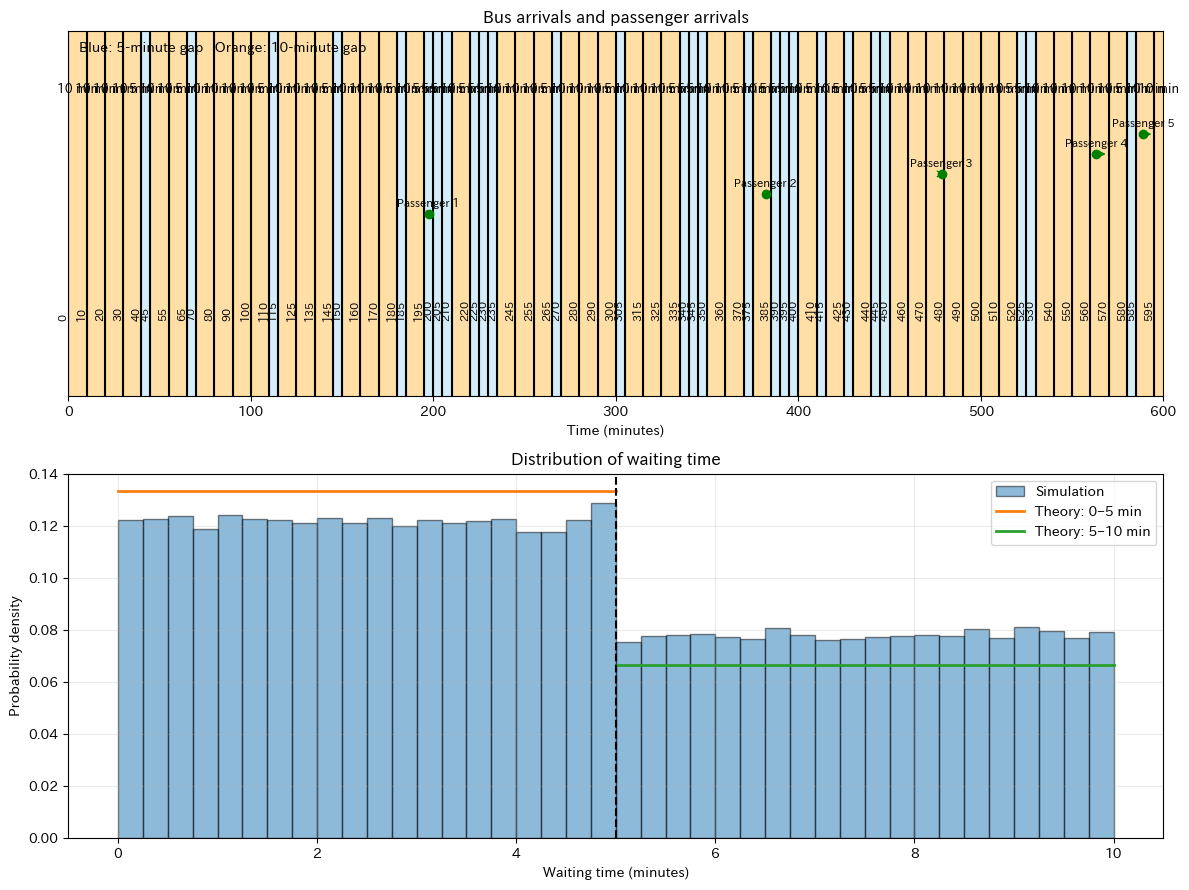

In [209]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# 1. バスの運行をシミュレーションする
# ==================================================

#np.random.seed(42)

# バスの間隔は、5分または10分。それぞれ確率1/2
T = 600  # 観察する時間：60分

bus_times = [0]

# バスの到着時刻を作る
# 観察時間60分を過ぎても、次のバスが来るまで作る
while bus_times[-1] <= T:
    interval = np.random.choice([5, 10])
    bus_times.append(bus_times[-1] + interval)

bus_times = np.array(bus_times)

print("バスの到着時刻（分）")
print(bus_times[bus_times <= T])


# ==================================================
# 2. 乗客がランダムな時刻に来る
# ==================================================

N = 100_000  # 乗客の人数
passenger_times = np.random.uniform(0, T, N)

# 各乗客が乗る「次のバス」の到着時刻を探す
next_indices = np.searchsorted(
    bus_times, passenger_times, side="right"
)
next_bus_times = bus_times[next_indices]

# 待ち時間 = 次のバスの時刻 - 乗客が来た時刻
waits = next_bus_times - passenger_times
wait_times = (
    bus_times[next_indices] - passenger_times
)


# ==================================================
# 3. 乗客が5分間隔・10分間隔のどちらに来たか
# ==================================================

# 乗客が来た時刻の直前のバスを探す
previous_indices = np.searchsorted(
    bus_times, passenger_times, side="right"
) - 1

# その直後のバスまでの間隔
gaps = bus_times[previous_indices + 1] - bus_times[previous_indices]

p_gap5 = np.mean(gaps == 5)
p_gap10 = np.mean(gaps == 10)

print("\n乗客が到着した区間")
print(f"5分間隔の区間にいた割合 : {p_gap5:.3f}")
print(f"10分間隔の区間にいた割合: {p_gap10:.3f}")


# ==================================================
# 4. 待ち時間を集計する
# ==================================================

p_wait5 = np.mean(waits <= 5)
p_wait_over5 = np.mean(waits > 5)

print("\n待ち時間")
print(f"5分以内にバスが来た割合: {p_wait5:.3f}")
print(f"5分を超えて待った割合  : {p_wait_over5:.3f}")
print(f"平均待ち時間            : {np.mean(waits):.3f} 分")


# ==================================================
# 5. グラフを描く
# ==================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# ---------- 上段：バスと乗客の時刻 ----------
ax = axes[0]
ax.set_title("Bus arrivals and passenger arrivals")
ax.set_xlim(0, T)
ax.set_ylim(-0.4, 1.8)
ax.set_xlabel("Time (minutes)")
ax.set_yticks([])

# 5分間隔・10分間隔の区間を色分け
for i in range(len(bus_times) - 1):
    start = bus_times[i]
    end = bus_times[i + 1]

    if start >= T:
        break

    end_visible = min(end, T)
    color = "skyblue" if end - start == 5 else "orange"

    ax.axvspan(start, end_visible, color=color, alpha=0.35)
    ax.text(
        (start + end_visible) / 2, 1.45,
        f"{end - start} min",
        ha="center", va="center", fontsize=9
    )

# バスの到着時刻
for t in bus_times:
    if t <= T:
        ax.axvline(t, color="black", linewidth=1.5)
        ax.text(t, 0.05, f"{t:g}", rotation=90,
                ha="right", va="bottom", fontsize=8)

# 例として乗客5人を表示
example_times = np.sort(
    np.random.uniform(0, T, 5)
)

for j, t in enumerate(example_times):
    next_bus = bus_times[
        np.searchsorted(bus_times, t, side="right")
    ]
    y = 0.7 + j * 0.12

    ax.plot(t, y, "o", color="green")
    ax.annotate(
        "",
        xy=(next_bus, y),
        xytext=(t, y),
        arrowprops=dict(arrowstyle="->", color="green")
    )
    ax.text(t, y + 0.04, f"Passenger {j+1}",
            fontsize=8, ha="center")

ax.text(
    0.01, 0.97,
    "Blue: 5-minute gap   Orange: 10-minute gap",
    transform=ax.transAxes, va="top"
)

# ---------- 下段：待ち時間の分布 ----------
ax = axes[1]

bins = np.linspace(0, 10, 41)

ax.hist(
    wait_times, bins=bins, density=True,
    alpha=0.5, edgecolor="black",
    label="Simulation"
)

# 理論上の確率密度
x1 = np.linspace(0, 5, 100)
x2 = np.linspace(5, 10, 100)

ax.plot(x1, np.full_like(x1, 2/15),
        linewidth=2, label="Theory: 0–5 min")
ax.plot(x2, np.full_like(x2, 1/15),
        linewidth=2, label="Theory: 5–10 min")

ax.axvline(5, linestyle="--", color="black")
ax.set_title("Distribution of waiting time")
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Probability density")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

バスの間隔の発生回数
5分: 49934
10分: 50066


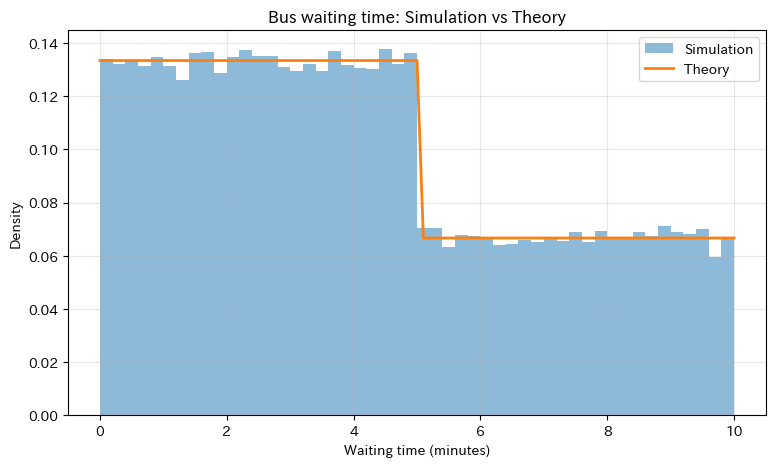

In [210]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ============================================================
# 1. バスの間隔を10万回発生させる
#    5分と10分は、それぞれ確率1/2
# ============================================================

n = 100_000

intervals = np.random.choice(
    [5, 10], size=n, p=[0.5, 0.5]
)
bus_times = np.concatenate(([0], np.cumsum(intervals)))

print("バスの間隔の発生回数")
print("5分:", np.sum(intervals == 5))
print("10分:", np.sum(intervals == 10))

# ============================================================
# 2. 各バスの間隔の中で、乗客がランダムな時刻に到着
# ============================================================
n_passengers = 100_000

arrival_times = np.random.uniform(
    0, bus_times[-1], size=n_passengers
    )

# 乗客の到着後、最初に来るバスを探す
next_bus_indices = np.searchsorted(
    bus_times, arrival_times, side="right"
    )


wait_times = (
    bus_times[next_bus_indices] - arrival_times
)
# ============================================================
# 3. 理論分布とシミュレーションを比較
# ============================================================

x = np.linspace(0, 10, 101)

density_theory = np.where(
    x <= 5, 2 / 15, 1 / 15
)

plt.figure(figsize=(9, 5))

plt.hist(
    wait_times,
    bins=np.linspace(0, 10, 51),
    density=True,
    alpha=0.5,
    label="Simulation"
)

plt.plot(
    x, density_theory,
    linewidth=2,
    label="Theory"
)

plt.xlabel("Waiting time (minutes)")
plt.ylabel("Density")
plt.title("Bus waiting time: Simulation vs Theory")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [211]:
n = 300

intervals = np.random.choice([5,10], size=n, p=[0.5,0.5])
intervals

array([ 5,  5,  5,  5,  5,  5,  5, 10, 10,  5,  5,  5,  5,  5,  5,  5, 10,
       10,  5,  5, 10,  5, 10,  5,  5,  5, 10,  5,  5,  5,  5,  5, 10, 10,
       10, 10, 10, 10, 10,  5, 10,  5, 10,  5, 10, 10, 10,  5,  5, 10, 10,
       10, 10,  5, 10, 10, 10,  5, 10, 10, 10,  5,  5,  5, 10,  5,  5,  5,
       10, 10, 10, 10, 10, 10, 10, 10, 10,  5,  5,  5, 10, 10, 10, 10, 10,
       10, 10, 10,  5, 10,  5, 10,  5, 10, 10, 10, 10, 10, 10, 10, 10,  5,
       10,  5, 10,  5, 10, 10,  5, 10,  5,  5,  5,  5,  5, 10, 10, 10, 10,
       10, 10,  5,  5, 10,  5,  5, 10, 10, 10, 10, 10, 10,  5, 10, 10,  5,
       10, 10,  5,  5, 10, 10,  5,  5, 10, 10, 10,  5, 10, 10,  5,  5,  5,
       10, 10, 10,  5,  5,  5,  5,  5,  5,  5,  5, 10, 10, 10, 10, 10,  5,
       10, 10, 10, 10, 10, 10,  5, 10, 10, 10, 10, 10,  5,  5,  5, 10, 10,
        5,  5,  5, 10,  5,  5, 10,  5, 10,  5,  5, 10, 10, 10, 10,  5,  5,
        5,  5,  5, 10,  5,  5, 10,  5, 10, 10, 10,  5, 10, 10,  5,  5,  5,
        5,  5, 10,  5,  5

In [212]:
bus_times = np.concatenate(([0], np.cumsum(intervals)))
bus_times

array([   0,    5,   10,   15,   20,   25,   30,   35,   45,   55,   60,
         65,   70,   75,   80,   85,   90,  100,  110,  115,  120,  130,
        135,  145,  150,  155,  160,  170,  175,  180,  185,  190,  195,
        205,  215,  225,  235,  245,  255,  265,  270,  280,  285,  295,
        300,  310,  320,  330,  335,  340,  350,  360,  370,  380,  385,
        395,  405,  415,  420,  430,  440,  450,  455,  460,  465,  475,
        480,  485,  490,  500,  510,  520,  530,  540,  550,  560,  570,
        580,  585,  590,  595,  605,  615,  625,  635,  645,  655,  665,
        675,  680,  690,  695,  705,  710,  720,  730,  740,  750,  760,
        770,  780,  790,  795,  805,  810,  820,  825,  835,  845,  850,
        860,  865,  870,  875,  880,  885,  895,  905,  915,  925,  935,
        945,  950,  955,  965,  970,  975,  985,  995, 1005, 1015, 1025,
       1035, 1040, 1050, 1060, 1065, 1075, 1085, 1090, 1095, 1105, 1115,
       1120, 1125, 1135, 1145, 1155, 1160, 1170, 11

In [213]:
print(np.sum(intervals == 5), np.sum(intervals == 10))

144 156


In [214]:
n2 = 1000

arrival_times = np.random.uniform(0, bus_times[-1], size=n2)


(0.0, 1.0)

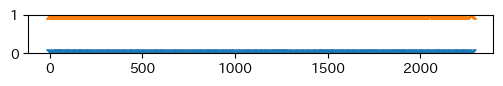

In [215]:
plt.figure(figsize=[6,0.5])

x = bus_times

y = np.zeros_like(x)

plt.plot(x,y,"x")

x = arrival_times
y = np.ones_like(x)

plt.plot(x,y,"x")

plt.ylim(0,1)

In [216]:
next_bus_indices = np.searchsorted(bus_times, arrival_times, side="right")

In [217]:
wait_times = bus_times[next_bus_indices] - arrival_times

(array([0.10824626, 0.14933975, 0.12829187, 0.14031923, 0.14232379,
        0.06615049, 0.07015962, 0.06414593, 0.06314365, 0.07015962]),
 array([8.55323826e-03, 1.00627820e+00, 2.00400317e+00, 3.00172814e+00,
        3.99945310e+00, 4.99717807e+00, 5.99490304e+00, 6.99262800e+00,
        7.99035297e+00, 8.98807794e+00, 9.98580290e+00]),
 <BarContainer object of 10 artists>)

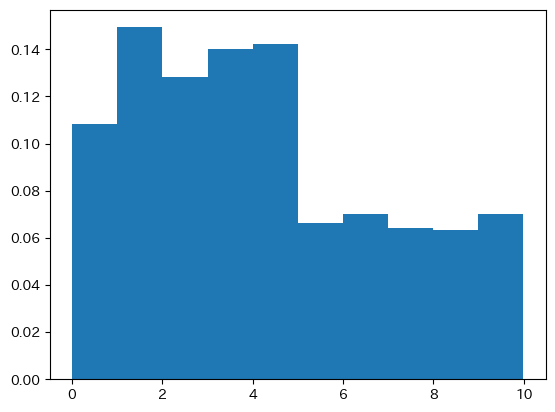

In [218]:
plt.hist(wait_times, density=True)


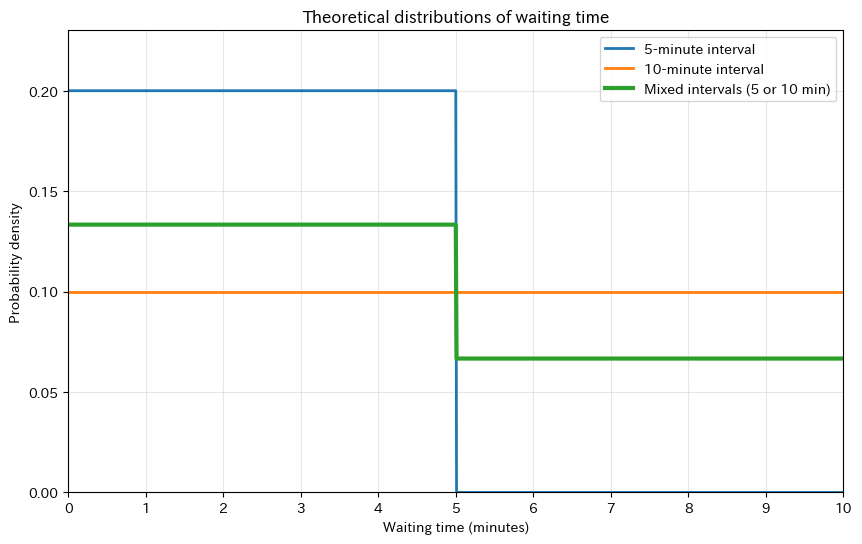

In [219]:
import numpy as np
import matplotlib.pyplot as plt

# 待ち時間の横軸（分）
w = np.linspace(0, 10, 1001)

# ① バスが5分間隔の場合
f_5 = np.where(w <= 5, 1/5, 0)

# ② バスが10分間隔の場合
f_10 = np.full_like(w, 1/10)

# ③ 5分・10分間隔が同じ確率で発生する場合
# ランダムな時刻に到着した乗客についての理論分布
f_mix = np.where(w <= 5, 2/15, 1/15)

# グラフ
plt.figure(figsize=(10, 6))

plt.plot(w, f_5, label="5-minute interval", linewidth=2)
plt.plot(w, f_10, label="10-minute interval", linewidth=2)
plt.plot(w, f_mix, label="Mixed intervals (5 or 10 min)",
         linewidth=3)

plt.xlim(0, 10)
plt.ylim(0, 0.23)
plt.xticks(np.arange(0, 11, 1))
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Probability density")
plt.title("Theoretical distributions of waiting time")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

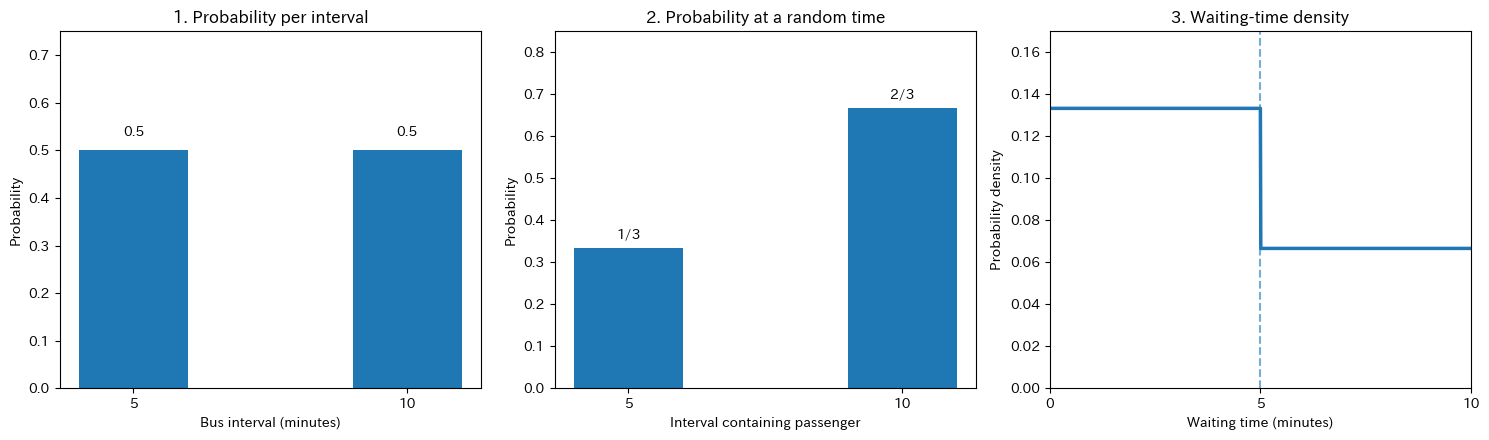

In [220]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. バスの「間隔が発生する確率」
axes[0].bar([5, 10], [0.5, 0.5], width=2)
axes[0].set_title("1. Probability per interval")
axes[0].set_xlabel("Bus interval (minutes)")
axes[0].set_ylabel("Probability")
axes[0].set_xticks([5, 10])
axes[0].set_ylim(0, 0.75)
axes[0].text(5, 0.53, "0.5", ha="center")
axes[0].text(10, 0.53, "0.5", ha="center")

# 2. ランダムな時刻に乗客がいる間隔
# 5分間隔10個、10分間隔10個と考える
# 5分間隔の合計時間 = 50分、10分間隔の合計時間 = 100分
axes[1].bar([5, 10], [1/3, 2/3], width=2)
axes[1].set_title("2. Probability at a random time")
axes[1].set_xlabel("Interval containing passenger")
axes[1].set_ylabel("Probability")
axes[1].set_xticks([5, 10])
axes[1].set_ylim(0, 0.85)
axes[1].text(5, 1/3 + 0.025, "1/3", ha="center")
axes[1].text(10, 2/3 + 0.025, "2/3", ha="center")

# 3. 待ち時間の確率密度
w = np.linspace(0, 10, 1001)
density = np.where(w <= 5, 2/15, 1/15)

axes[2].plot(w, density, linewidth=2.5)
axes[2].set_title("3. Waiting-time density")
axes[2].set_xlabel("Waiting time (minutes)")
axes[2].set_ylabel("Probability density")
axes[2].set_xlim(0, 10)
axes[2].set_ylim(0, 0.17)
axes[2].set_xticks([0, 5, 10])
axes[2].axvline(5, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

事前分布
5分間隔 : 0.500
10分間隔 : 0.500

事後分布
5分間隔 : 0.333
10分間隔 : 0.667

10分間隔の確率 = 0.6666666666666666


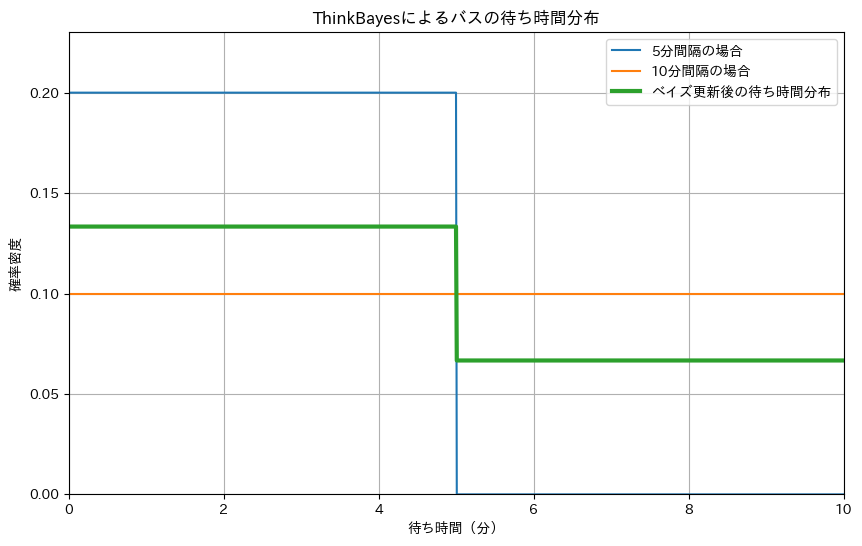

In [221]:
import thinkbayes
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. バスの間隔を仮説にする
#
# Hypothesis:
#     5  = 5分間隔
#     10 = 10分間隔
# ============================================================

class BusSuite(thinkbayes.Suite):

    def Likelihood(self, data, hypo):
        """
        乗客がランダムな時刻に来たとき、
        hypo 分間隔のバスに遭遇する尤度。

        区間が長いほど、ランダムな時刻が
        その区間に入る確率が高くなる。
        """

        return hypo


# ------------------------------------------------------------
# 2. 事前分布
# ------------------------------------------------------------

suite = BusSuite([5, 10])

suite.Set(5, 0.5)
suite.Set(10, 0.5)

print("事前分布")
for hypo, prob in suite.Items():
    print(f"{hypo}分間隔 : {prob:.3f}")


# ------------------------------------------------------------
# 3. 「乗客がランダムな時刻に来た」
#    というデータでUpdate
# ------------------------------------------------------------

suite.Update("random arrival")


print()
print("事後分布")
for hypo, prob in suite.Items():
    print(f"{hypo}分間隔 : {prob:.3f}")


# ============================================================
# 4. 事後分布を確認
# ============================================================

print()
print("10分間隔の確率 =", suite.Prob(10))


# ============================================================
# 5. 待ち時間の分布を作る
#
# 5分間隔なら:
#     0～5分に一様
#
# 10分間隔なら:
#     0～10分に一様
#
# そして、上で求めた事後確率
#     1/3 と 2/3
# で混ぜる。
# ============================================================

x = np.linspace(0, 10, 1001)

density_5 = np.where(x <= 5, 1 / 5, 0)

density_10 = np.ones_like(x) / 10

density_wait = (
    suite.Prob(5) * density_5
    + suite.Prob(10) * density_10
)


# ============================================================
# 6. グラフ
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    density_5,
    label="5分間隔の場合"
)

plt.plot(
    x,
    density_10,
    label="10分間隔の場合"
)

plt.plot(
    x,
    density_wait,
    linewidth=3,
    label="ベイズ更新後の待ち時間分布"
)

plt.xlabel("待ち時間（分）")
plt.ylabel("確率密度")

plt.title("ThinkBayesによるバスの待ち時間分布")

plt.xlim(0, 10)
plt.ylim(0, 0.23)

plt.grid(True)
plt.legend()

plt.show()

問題７−２：乗客がバス停に着くのが、パラメータラムダのポワソン仮定でうまくモデル化できると仮定する。あなたがバス停に着くと３人待っていたとしたら、直前のバスが到着してからの時間の事後確率分布はどうなるか。

========== 条件 ==========
乗客到着率 λ = 2.0 人/分
観測した人数 = 3 人

========== 分布の確認 ==========
事前分布の面積   = 0.667333
事後分布の面積   = 1.000000

========== 事後分布 ==========
事後平均 = 2.000 分
中央値 = 1.840 分
95%信用区間 = 0.540 ～ 4.380 分


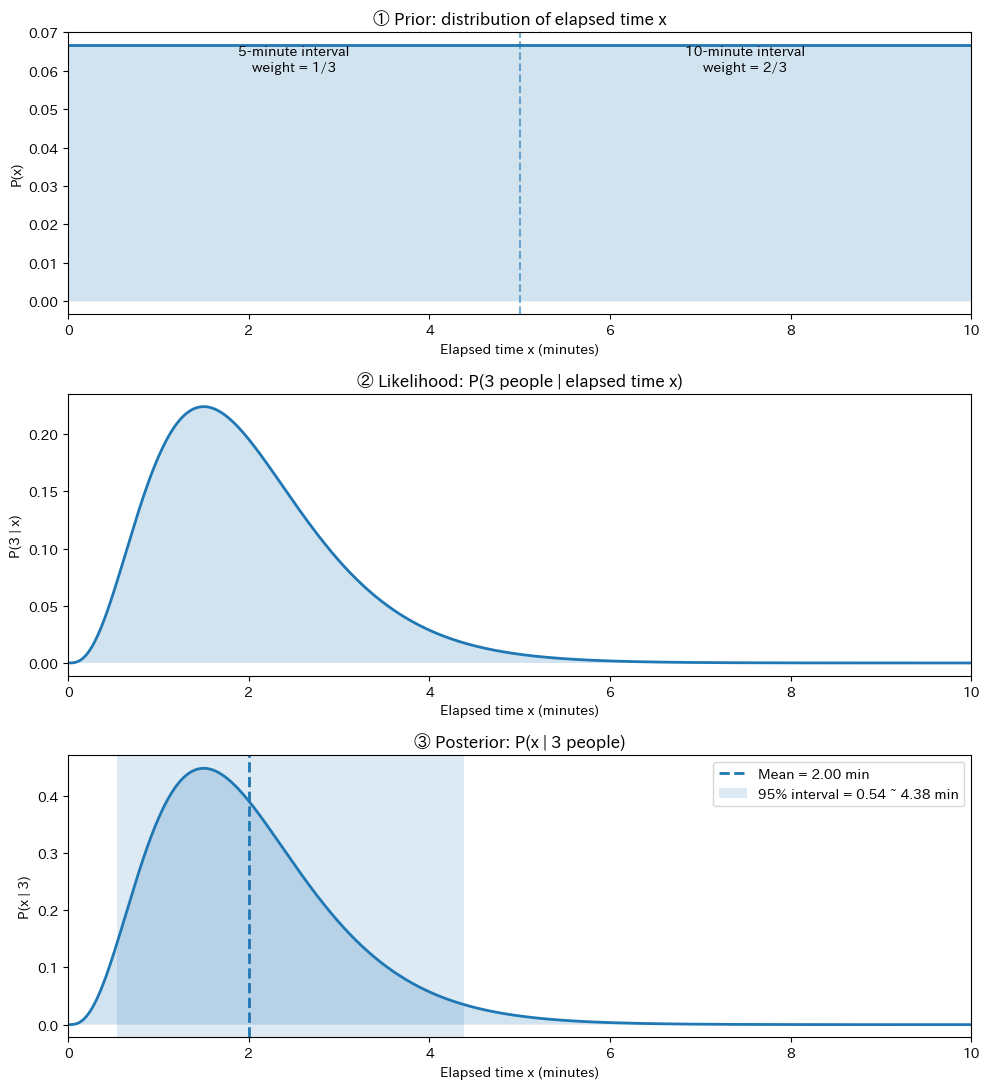

In [222]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial


# ============================================================
# 問題 7-2
#
# 「バス停に着いたら3人待っていた」
# → 直前のバスからの経過時間 x の事後分布を求める
# ============================================================


# ============================================================
# 1. パラメータ
# ============================================================

lam = 2.0       # 乗客の到着率 λ（人/分）
k = 3           # 観測した待ち人数

# x = 最後のバスから現在までの経過時間
x = np.linspace(0, 10, 1001)

dx = x[1] - x[0]


# ============================================================
# 2. 事前分布 P(x)
#
# 前の問題から：
#
# バス間隔を乗客が経験する確率
#   5分間隔  → 1/3
#   10分間隔 → 2/3
#
# その間隔の中では x は一様。
# ============================================================

prior = np.zeros_like(x)

# 0～5分
prior[x <= 5] = (1/3) * (1/5)

# 5～10分
prior[x > 5] = (2/3) * (1/10)


# ============================================================
# 3. 尤度 P(3 | x)
#
# x分間に3人到着する確率
#
# Poisson:
#
# P(k | λx)
# = exp(-λx) * (λx)^k / k!
# ============================================================

likelihood = (
    np.exp(-lam * x)
    * (lam * x) ** k
    / factorial(k)
)


# ============================================================
# 4. 事前 × 尤度
#
# ベイズの定理：
#
# posterior ∝ prior × likelihood
# ============================================================

unnormalized = prior * likelihood


# ============================================================
# 5. 正規化して事後分布にする
# ============================================================

posterior = (
    unnormalized
    / np.sum(unnormalized * dx)
)


# ============================================================
# 6. 数値を確認
# ============================================================

print("========== 条件 ==========")
print(f"乗客到着率 λ = {lam} 人/分")
print(f"観測した人数 = {k} 人")

print()
print("========== 分布の確認 ==========")
print(f"事前分布の面積   = {np.sum(prior * dx):.6f}")
print(f"事後分布の面積   = {np.sum(posterior * dx):.6f}")


# ============================================================
# 7. 事後分布の平均
# ============================================================

posterior_mean = np.sum(x * posterior * dx)

print()
print("========== 事後分布 ==========")
print(f"事後平均 = {posterior_mean:.3f} 分")


# ============================================================
# 8. 中央値と95%信用区間
# ============================================================

cdf = np.cumsum(posterior) * dx

median = x[np.searchsorted(cdf, 0.5)]
lower = x[np.searchsorted(cdf, 0.025)]
upper = x[np.searchsorted(cdf, 0.975)]

print(f"中央値 = {median:.3f} 分")
print(f"95%信用区間 = {lower:.3f} ～ {upper:.3f} 分")


# ============================================================
# 9. グラフ
#
#    ① 事前分布
#    ② 尤度
#    ③ 事後分布
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(10, 11))


# ------------------------------------------------------------
# ① Prior
# ------------------------------------------------------------

ax = axes[0]

ax.plot(x, prior, linewidth=2)
ax.fill_between(x, prior, alpha=0.2)

ax.axvline(5, linestyle="--", alpha=0.6)

ax.set_title("① Prior: distribution of elapsed time x")
ax.set_xlabel("Elapsed time x (minutes)")
ax.set_ylabel("P(x)")
ax.set_xlim(0, 10)

ax.text(
    2.5, 0.06,
    "5-minute interval\nweight = 1/3",
    ha="center"
)

ax.text(
    7.5, 0.06,
    "10-minute interval\nweight = 2/3",
    ha="center"
)


# ------------------------------------------------------------
# ② Likelihood
# ------------------------------------------------------------

ax = axes[1]

ax.plot(x, likelihood, linewidth=2)
ax.fill_between(x, likelihood, alpha=0.2)

ax.set_title("② Likelihood: P(3 people | elapsed time x)")
ax.set_xlabel("Elapsed time x (minutes)")
ax.set_ylabel("P(3 | x)")
ax.set_xlim(0, 10)


# ------------------------------------------------------------
# ③ Posterior
# ------------------------------------------------------------

ax = axes[2]

ax.plot(x, posterior, linewidth=2)
ax.fill_between(x, posterior, alpha=0.2)

ax.axvline(
    posterior_mean,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {posterior_mean:.2f} min"
)

ax.axvspan(
    lower,
    upper,
    alpha=0.15,
    label=f"95% interval = {lower:.2f} ~ {upper:.2f} min"
)

ax.set_title("③ Posterior: P(x | 3 people)")
ax.set_xlabel("Elapsed time x (minutes)")
ax.set_ylabel("P(x | 3)")
ax.set_xlim(0, 10)
ax.legend()


plt.tight_layout()
plt.show()

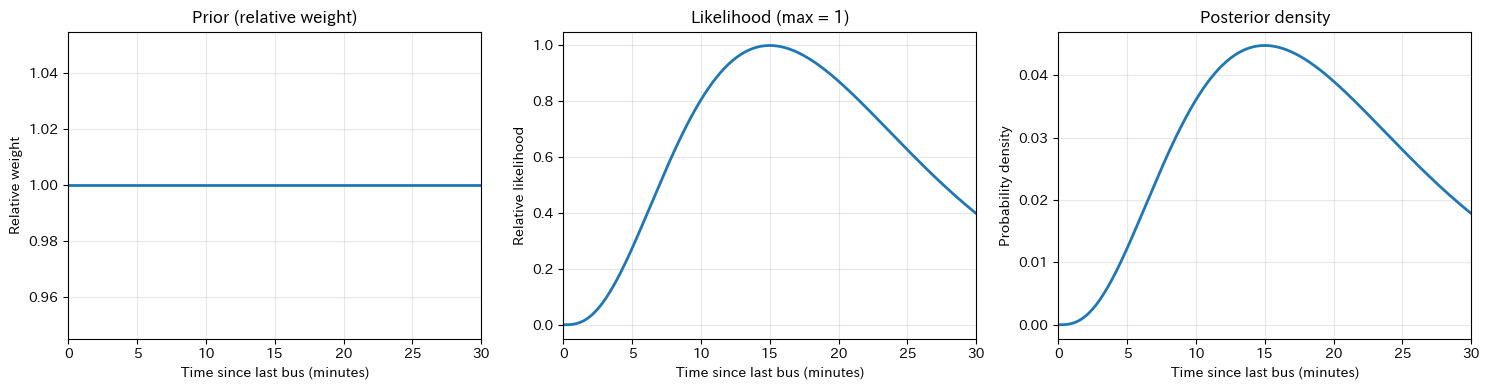

尤度の最大位置: 15.0 分
事後分布の最頻値: 15.0 分
事後分布の平均: 20.0 分


In [223]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 条件
# ==========================================
lam = 0.2       # 例として設定：1分あたり0.2人
k = 3           # 観測した乗客数
t = np.linspace(0, 30, 1001)

# ==========================================
# 2. Prior：経過時間に一様な重みを置く
#    ※無限範囲では正規化できない事前分布
# ==========================================
prior = np.ones_like(t)

# ==========================================
# 3. Likelihood：3人が到着する確率
# ==========================================
likelihood = (lam * t)**k * np.exp(-lam * t) / 6

# グラフ比較用に最大値を1にそろえる
likelihood_relative = likelihood / likelihood.max()

# ==========================================
# 4. Posterior：一様な事前分布で更新
#    ガンマ分布 Gamma(shape=4, rate=lam)
# ==========================================
posterior = (
    lam**(k + 1) * t**k * np.exp(-lam * t) / 6
)

# ==========================================
# 5. 描画
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(t, prior, linewidth=2)
axes[0].set_title("Prior (relative weight)")
axes[0].set_ylabel("Relative weight")

axes[1].plot(t, likelihood_relative, linewidth=2)
axes[1].set_title("Likelihood (max = 1)")
axes[1].set_ylabel("Relative likelihood")

axes[2].plot(t, posterior, linewidth=2)
axes[2].set_title("Posterior density")
axes[2].set_ylabel("Probability density")

for ax in axes:
    ax.set_xlabel("Time since last bus (minutes)")
    ax.set_xlim(0, 30)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"尤度の最大位置: {k / lam:.1f} 分")
print(f"事後分布の最頻値: {k / lam:.1f} 分")
print(f"事後分布の平均: {(k + 1) / lam:.1f} 分")

## 問題7-3 

あなたが、新しい環境での昆虫の分布のサンプルを採取している生物学者だと仮定しよう。調査領域に１００個の罠を仕掛け、次の日にそれらを調べる。３７の罠に作動した痕跡があり、かかったのは一匹だった。罠は作動すると、設定し直すまで昆虫を捕まえることができない。２日間で罠を仕掛け直したとすると、幾つの罠が作動するものと期待するか。罠の個数の事後確率分布を計算せよ。

事前分布の仮定: p は一様分布
観測データ: 37/100 個が作動
事後分布の平均 p: 0.3725
2日間で作動する罠の期待個数: 60.40 個
最も確率が高い個数: 61 個
予測確率の合計: 1.000000


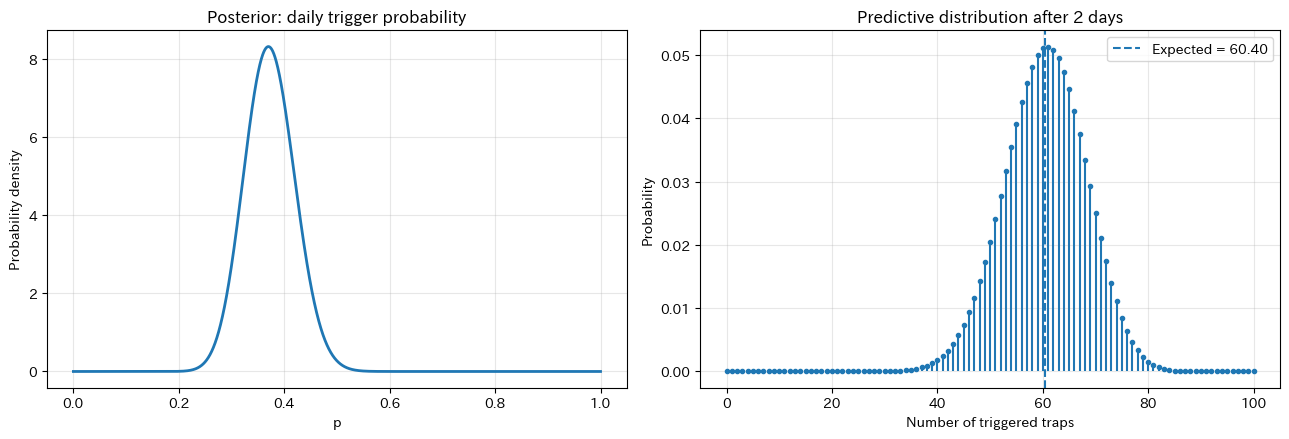

In [224]:
import math

# ==================================================
# 1. 観測データ
# ==================================================
n_traps = 100
observed = 37
days_future = 2

# ==================================================
# 2. p の事前分布
#    1日で罠が作動する確率 p は一様と仮定
# ==================================================
p = np.linspace(0.0001, 0.9999, 10001)
dp = p[1] - p[0]

# ==================================================
# 3. Likelihood（尤度）
#    100個中37個が作動する確率
#    二項係数は p によらないので省略
# ==================================================
log_likelihood = (
    observed * np.log(p)
    + (n_traps - observed) * np.log1p(-p)
)

# 数値が小さくなりすぎないように最大値を引く
likelihood = np.exp(
    log_likelihood - np.max(log_likelihood)
)

# ==================================================
# 4. Posterior（事後分布）
#    Prior × Likelihood を正規化
# ==================================================
posterior_weight = likelihood / likelihood.sum()

# 確率密度として描くための値
posterior_density = posterior_weight / dp

# ==================================================
# 5. 2日間で罠が作動する確率
# ==================================================
q = 1 - (1 - p) ** days_future

# ==================================================
# 6. Posterior predictive distribution
#    2日後に作動している罠の個数 K
#    K | p は Binomial(100, q)
# ==================================================
k_values = np.arange(n_traps + 1)

# 二項係数の対数
log_comb = np.array([
    math.lgamma(n_traps + 1)
    - math.lgamma(int(k) + 1)
    - math.lgamma(n_traps - int(k) + 1)
    for k in k_values
])

# 各 p に対して、0～100個の確率を計算
log_predictive = (
    log_comb[None, :]
    + np.log(q)[:, None] * k_values[None, :]
    + np.log1p(-q)[:, None]
      * (n_traps - k_values)[None, :]
)

conditional_pmf = np.exp(log_predictive)

# 事後分布の重みで平均を取り、予測分布を得る
predictive_pmf = posterior_weight @ conditional_pmf

# 正規化（丸め誤差を補正）
predictive_pmf /= predictive_pmf.sum()

# ==================================================
# 7. 結果の確認
# ==================================================
expected = np.sum(k_values * predictive_pmf)
most_likely = k_values[np.argmax(predictive_pmf)]

print(f"事前分布の仮定: p は一様分布")
print(f"観測データ: {observed}/{n_traps} 個が作動")
print(f"事後分布の平均 p: {np.sum(p * posterior_weight):.4f}")
print(f"2日間で作動する罠の期待個数: {expected:.2f} 個")
print(f"最も確率が高い個数: {most_likely} 個")
print(f"予測確率の合計: {predictive_pmf.sum():.6f}")

# ==================================================
# 8. グラフ
# ==================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 左：p の事後分布
axes[0].plot(p, posterior_density, linewidth=2)
axes[0].set_title("Posterior: daily trigger probability")
axes[0].set_xlabel("p")
axes[0].set_ylabel("Probability density")
axes[0].grid(True, alpha=0.3)

# 右：2日後に作動する罠の個数の予測分布
axes[1].vlines(
    k_values, 0, predictive_pmf,
    linewidth=1.5
)
axes[1].plot(
    k_values, predictive_pmf,
    "o", markersize=3
)
axes[1].axvline(
    expected, linestyle="--",
    label=f"Expected = {expected:.2f}"
)
axes[1].set_title("Predictive distribution after 2 days")
axes[1].set_xlabel("Number of triggered traps")
axes[1].set_ylabel("Probability")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [225]:
import math

class TrapRate(thinkbayes.Suite):
    def Likelihood(self, data, hypo):
        n, k = data
        p = hypo

        return (
            math.comb(n, k)
            * p**k
            * (1 - p) ** (n - k)  
        )
    

In [226]:
# Prior
p_grid = np.linspace(0,1,1001)

prior = TrapRate(name="Prior")
for p in p_grid:
    prior.Set(float(p), 1)
prior.Normalize()

# posterior
posterior = prior.Copy(name="Posterior")
posterior.Update((n_traps, observed))

0.009891099000009892

In [227]:
# 2日間で作動する確率

predictive = thinkbayes.Pmf(name="Predictive")
for p, prob_p in posterior.Items():
    q = 1 - (1-p)**days_future

    for k in range(n_traps + 1):
        q = 1-(1-p)**days_future
    for k in range(n_traps + 1):
        prob_k = (
            math.comb(n_traps, k)
            * q**k
            * (1-q)**(n_traps - k)
        )

        predictive.Incr(k, prob_p * prob_k)

predictive.Normalize()



0.9999999999999997

In [228]:
# 結果

expected = predictive.Mean()
most_likely = predictive.MaximumLikelihood()

p_mean = posterior.Mean()
p_mode = posterior.MaximumLikelihood()

print(f"事後分布の平均 p : {p_mean:.4f}")
print(f"事後分布の最頻値 p : {p_mode:.3f}")
print(f"2日間で作動する期待個数 : {expected:.2f}個")
print(f"最も確率が高い個数 : {most_likely}個")
print(f"予測確率の合計 : {predictive.Total():.6f}")

事後分布の平均 p : 0.3725
事後分布の最頻値 p : 0.370
2日間で作動する期待個数 : 60.40個
最も確率が高い個数 : 61個
予測確率の合計 : 1.000000


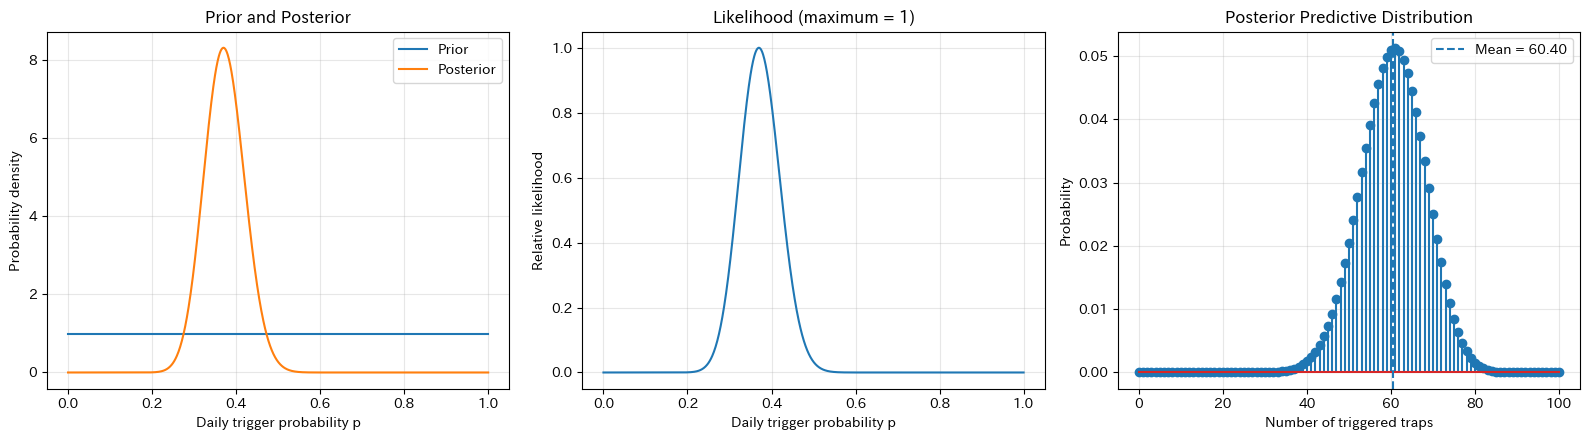

In [229]:
# ==================================================
# 7. 描画用データ
# ==================================================
prior_items = sorted(prior.Items())
post_items = sorted(posterior.Items())
pred_items = sorted(predictive.Items())

p_values = np.array([x for x, prob in post_items])
prior_probs = np.array([prob for x, prob in prior_items])
post_probs = np.array([prob for x, prob in post_items])

# pの離散確率を、密度として比較する
dp = p_grid[1] - p_grid[0]
prior_density = prior_probs / dp
post_density = post_probs / dp

# 尤度（比較しやすいよう最大値を1にする）
likelihood = np.array([
    posterior.Likelihood((n_traps, observed), p)
    for p in p_values
])
likelihood_relative = likelihood / likelihood.max()

k_values = np.array([x for x, prob in pred_items])
predictive_probs = np.array([prob for x, prob in pred_items])

# ==================================================
# 8. グラフ
# ==================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 左：事前分布と事後分布
axes[0].plot(
    p_values, prior_density,
    label="Prior"
)
axes[0].plot(
    p_values, post_density,
    label="Posterior"
)
axes[0].set_title("Prior and Posterior")
axes[0].set_xlabel("Daily trigger probability p")
axes[0].set_ylabel("Probability density")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 中：尤度
axes[1].plot(p_values, likelihood_relative)
axes[1].set_title("Likelihood (maximum = 1)")
axes[1].set_xlabel("Daily trigger probability p")
axes[1].set_ylabel("Relative likelihood")
axes[1].grid(True, alpha=0.3)

# 右：2日後に作動している罠の個数
axes[2].stem(k_values, predictive_probs)
axes[2].axvline(
    expected, linestyle="--",
    label=f"Mean = {expected:.2f}"
)
axes[2].set_title("Posterior Predictive Distribution")
axes[2].set_xlabel("Number of triggered traps")
axes[2].set_ylabel("Probability")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [230]:
from scipy.stats import beta, binom
# 基本設定
n_traps = 100
n_observed = 100
k_observed = 37
days_future = 2

# pの事後分布
# 一様事前分布 + 二項分布の尤度
# Beta(38, 64)
p_grid = np.linspace(0.0001, 0.9999, 1001)

p_density = beta.pdf(
    p_grid,
    k_observed + 1,
    n_observed - k_observed + 1
)

# pの各候補に対する事後確率の重み
p_weights = p_density / np.sum(p_density)



In [231]:
# １日あたりのpを２日間の累積確率qに変換
q_grid = 1 - (1 - p_grid)**days_future

# qの確率密度
# q 
q_density = p_density / (days_future * (1-p_grid))

# 正規化
q_area = np.sum(
    (q_density[:-1] * q_density[1:]) / 2
    * np.diff(q_grid)
)

q_density = q_density / q_area

In [232]:
# qの候補ごとに二項分布を計算

k_values = np.arange(n_traps + 1)

# 各qについて、作動数0〜100個の確率を計算
conditional_pmf = binom.pmf(
    k_values[None, :],
    n_traps,
    q_grid[:,None]
)

# グラフには、qの事後分布の10%, 50%, 90%点を表示
cumlative_weights = np.cumsum(p_weights)

q_levels = [0.10, 0.50, 0.90]
p_indices = [
    np.searchsorted(cumlative_weights, level)
    for level in q_levels
]
selected_q = q_grid[p_indices]

In [233]:
# 最終的な予測分布
# qの不確実性を考慮して、二項分布を平均する
predictive_pmf = np.sum(
    p_weights[:,None] * conditional_pmf,
    axis=0
)

expected_count = np.sum(k_values * predictive_pmf)

二日間に作動する罠の期待値： 60.40
予測確率の合計： 1.000000


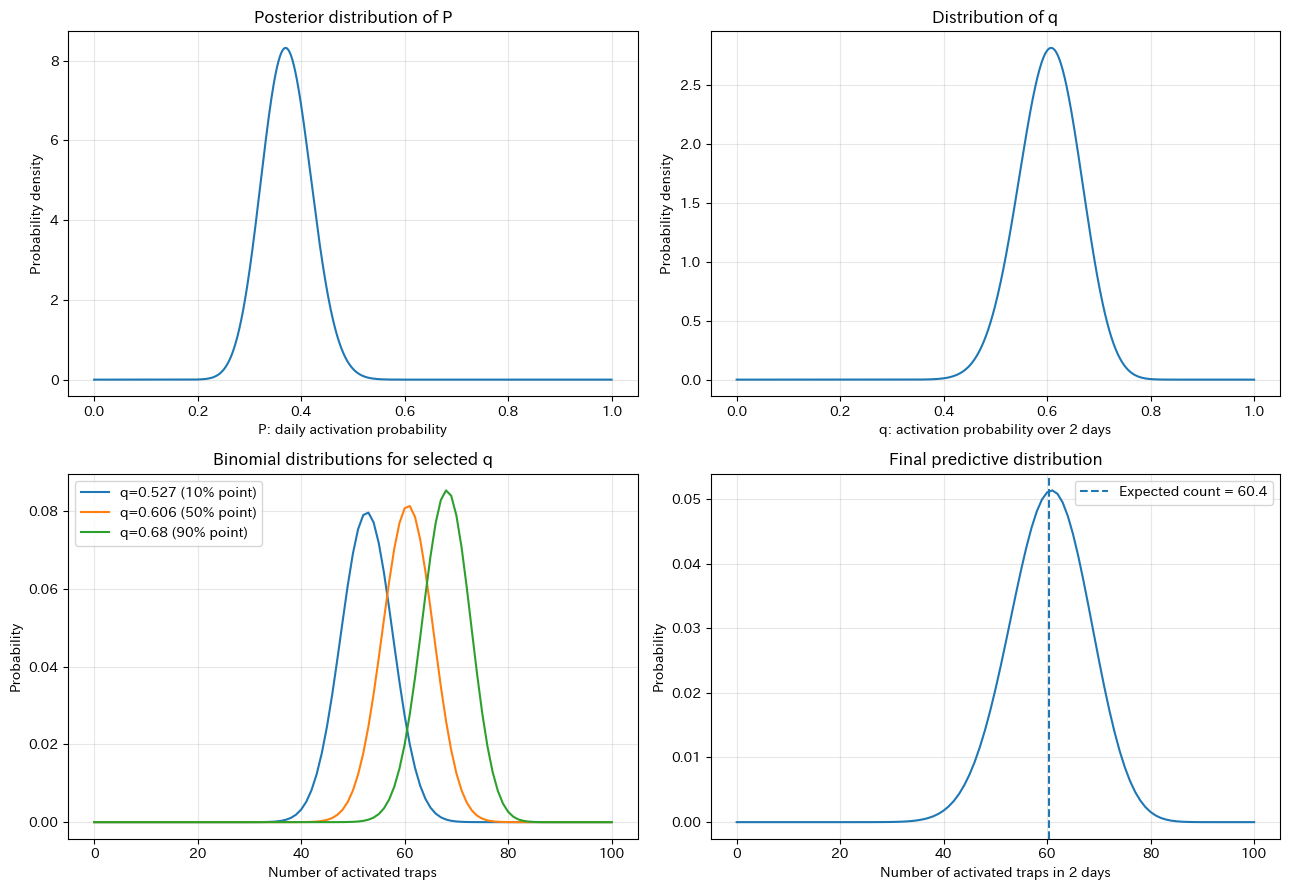

In [234]:
# グラフ
fig, axes = plt.subplots(2,2,figsize=(13,9))

# Pの事後分布
axes[0,0].plot(p_grid, p_density)
axes[0,0].set_title("Posterior distribution of P")
axes[0,0].set_xlabel("P: daily activation probability")
axes[0,0].set_ylabel("Probability density")
axes[0,0].grid(alpha=0.3)

axes[0,1].plot(q_grid, q_density)
axes[0,1].set_title("Distribution of q")
axes[0,1].set_xlabel("q: activation probability over 2 days")
axes[0,1].set_ylabel("Probability density")
axes[0,1].grid(alpha=0.3)

for level, q_value in zip(q_levels, selected_q):
    pmf = binom.pmf(k_values, n_traps, q_value)
    axes[1,0].plot(
        k_values, pmf, 
        label=f"q={q_value:.3} ({level:.0%} point)"
    )
axes[1,0].set_title("Binomial distributions for selected q")
axes[1,0].set_xlabel("Number of activated traps")
axes[1,0].set_ylabel("Probability")
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

axes[1,1].plot(k_values, predictive_pmf)
axes[1,1].axvline(
    expected_count,
    linestyle="--",
    label=f"Expected count = {expected_count:.1f}"
)
axes[1,1].set_title("Final predictive distribution")
axes[1,1].set_xlabel("Number of activated traps in 2 days")
axes[1,1].set_ylabel("Probability")
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)

plt.tight_layout()

print(f"二日間に作動する罠の期待値： {expected_count:.2f}")
print(f"予測確率の合計： {predictive_pmf.sum():.6f}")

In [235]:
from scipy.stats import beta, binom

# 問題の設定
n_traps = 100
observed = 17
days_future = 2

# 一日当たりの作動確率 p の事後分布
p_grid = np.linspace(0,1,101)
prior_density = beta.pdf(p_grid,1,1)
p_density = beta.pdf(p_grid,38,64)

# pの各値に対する重み：p_gridは等間隔なので、密度を合計１になるように正規化する
p_weights = p_density / np.sum(p_density)



In [236]:
# 1日当たりの確率 p から、２日間の確率 q を計算
# 2日間とも作動しない確率は (1-p)**2
# 少なくとも一回作動する確率は 1 - (1-p)**2

q_grid = 1 - (1-p_grid)**days_future

# ２日後に作動している個数の予測分布
k_values = np.arange(n_traps + 1)

# pの各値に対して、２日後の作動個数の確率を計算
conditional_pmf = binom.pmf(
    k_values[None,:],
    n_traps,
    q_grid[:,None]
)

# pの事後分布の重みを使って、予測確率を平均する
predictive_pmf = np.sum(p_weights[:,None]*conditional_pmf,
axis=0)

# 念の為、合計が１になることを確認
predictive_pmf = predictive_pmf / predictive_pmf.sum()

print(f"予測確率の合計： {predictive_pmf.sum():.6f}")

予測確率の合計： 1.000000


In [237]:
expected_count = np.sum(k_values * predictive_pmf)

cdf = np.cumsum(predictive_pmf)
lower = k_values[np.searchsorted(cdf, 0.025)]
upper = k_values[np.searchsorted(cdf, 0.975)]

print(f"２日後に作動する個数の期待値：{expected_count:.2f} 個")
print(f"95% 予測区間： {lower}〜{upper}")

２日後に作動する個数の期待値：60.40 個
95% 予測区間： 45〜75


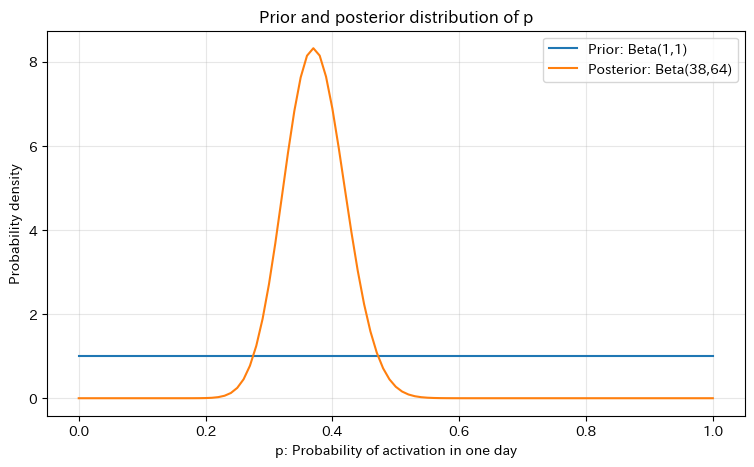

In [238]:
plt.figure(figsize=(9,5))

plt.plot(
    p_grid, prior_density,
    label="Prior: Beta(1,1)"
)

plt.plot(
    p_grid, p_density,
    label="Posterior: Beta(38,64)"
)

plt.xlabel("p: Probability of activation in one day")
plt.ylabel("Probability density")
plt.title("Prior and posterior distribution of p")
plt.legend()
plt.grid(alpha=0.3)


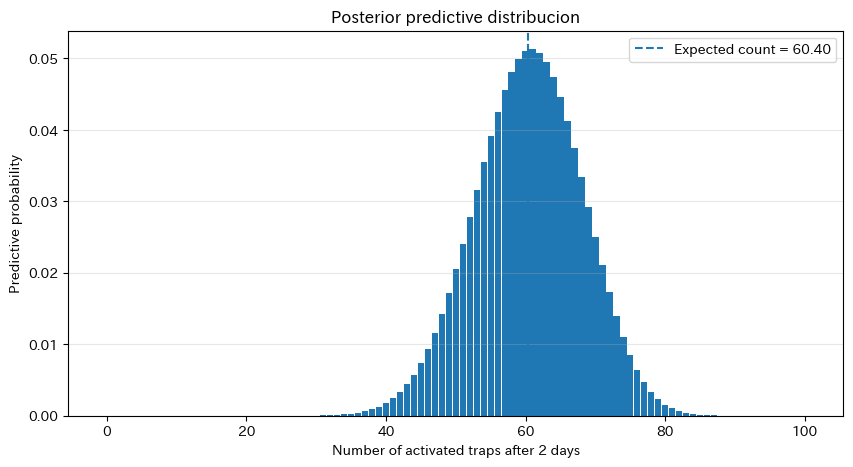

In [239]:
plt.figure(figsize=(10,5))

plt.bar(k_values, predictive_pmf, width=0.9)
plt.axvline(
    expected_count,
    linestyle="--",
    label=f"Expected count = {expected_count:.2f}"
)

plt.xlabel("Number of activated traps after 2 days")
plt.ylabel("Predictive probability")
plt.title("Posterior predictive distribucion")
plt.legend()
plt.grid(axis="y", alpha=0.3)

In [240]:
p_grid = np.linspace(0,1,101)
p_density = np.ones_like(p_grid)

q_grid = p_grid**2

q_density = np.full_like(p_grid,np.nan)

q_density[1:] = (
    p_density[1:] / 
    (2 * p_grid[1:])
)

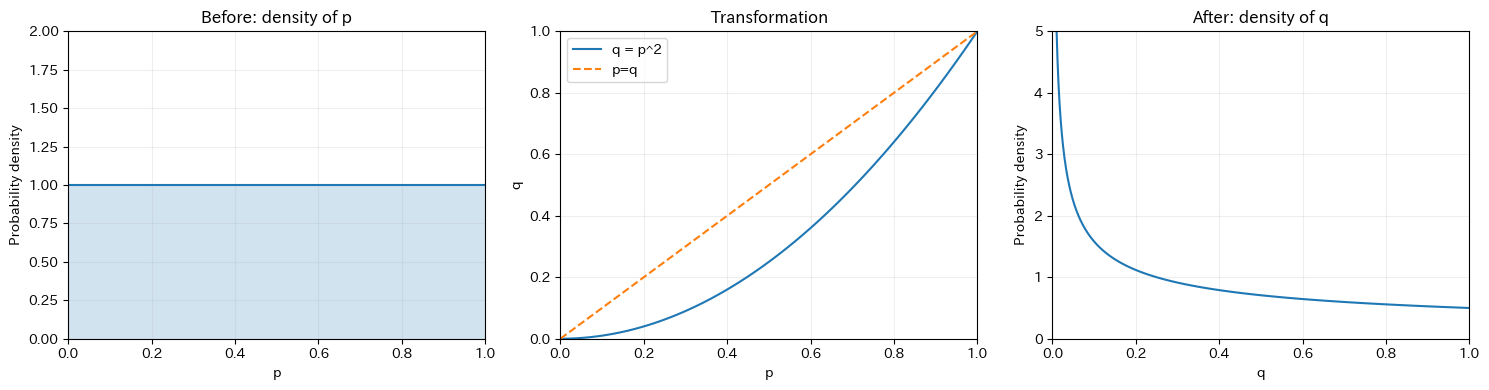

In [247]:
fig, axes = plt.subplots(1,3,figsize=(15,4))

axes[0].plot(p_grid, p_density)
axes[0].fill_between(p_grid, p_density, alpha=0.2)
axes[0].set_title("Before: density of p")
axes[0].set_xlabel("p")
axes[0].set_ylabel("Probability density")
axes[0].set_xlim(0,1)
axes[0].set_ylim(0,2)
axes[0].grid(alpha=0.2)

axes[1].plot(p_grid, q_grid, label="q = p^2")
axes[1].plot(p_grid, p_grid, "--", label="p=q")
axes[1].set_title("Transformation")
axes[1].set_xlabel("p")
axes[1].set_ylabel("q")
axes[1].set_xlim(0,1)
axes[1].set_ylim(0,1)
axes[1].legend()
axes[1].grid(alpha=0.2)

axes[2].plot(q_grid[1:],q_density[1:])
axes[2].set_title("After: density of q")
axes[2].set_xlabel("q")
axes[2].set_ylabel("Probability density")
axes[2].set_xlim(0,1)
axes[2].set_ylim(0,5)
axes[2].grid(alpha=0.2)

plt.tight_layout()

In [242]:
prob_p = 0.5

mask = q_grid[1:] <= 0.25

prob_q = np.trapz(
    q_density[1:][mask],
    q_grid[1:][mask]
)

print(f"P(p <= 0.5) = {prob_p:.3f}")
print(f"P(q <= 0.25) = {prob_q:.3f}")

P(p <= 0.5) = 0.500
P(q <= 0.25) = 0.492


#### 問題 7-4 
あなたが共用部分に100個の電球があるアパートの管理人だとする。電球が切れたら交換するのが役目だ。

1月1日には全ての電球がついていた。2月1日に点検したところ、3つの電球が切れていた。4月1日に戻った時、幾つの電球が切れていると想定するか。



In [250]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. 1月の観測データ
# ============================================================
n_bulbs = 100
n_failed = 3
n_working = n_bulbs - n_failed

# 故障確率 p の候補
p_grid = np.linspace(0.00001, 0.99999, 50001)
dp = p_grid[1] - p_grid[0]

# ============================================================
# 2. 事前分布：p は 0～1 の一様分布
# ============================================================
prior = np.ones_like(p_grid)
prior = prior / prior.sum()

# ============================================================
# 3. 尤度：100個中3個が故障する確率
#    尤度に共通する二項係数は、正規化時に相殺される
# ============================================================
log_likelihood = (
    n_failed * np.log(p_grid)
    + n_working * np.log1p(-p_grid)
)

# 数値計算が不安定にならないよう最大値を引く
likelihood = np.exp(log_likelihood - log_likelihood.max())

# ============================================================
# 4. 事後分布：事前分布 × 尤度
# ============================================================
posterior = prior * likelihood
posterior = posterior / posterior.sum()

# ============================================================
# 5. 4月1日までの故障数の予測分布
# ============================================================
# p が1か月の故障確率なら、2か月間の故障確率は
# q = 1 - (1-p)**2
q_grid = 1 - (1 - p_grid)**2

def predictive_pmf(n, q_grid, posterior):
    """未知の故障確率を事後分布で平均し、故障数を予測する。"""
    k = np.arange(n + 1)

    # 二項分布の対数確率
    log_comb = (
        np.array([
            np.math.lgamma(n + 1)
            - np.math.lgamma(int(ki) + 1)
            - np.math.lgamma(n - int(ki) + 1)
            for ki in k
        ])
        if False else
        np.array([
            sum([]) for _ in []
        ])
    )

事後分布の平均故障確率（1か月）: 0.0392
2月1日に交換した場合の4月1日の期待故障数: 7.65
交換しなかった場合の4月1日の期待故障数: 10.42


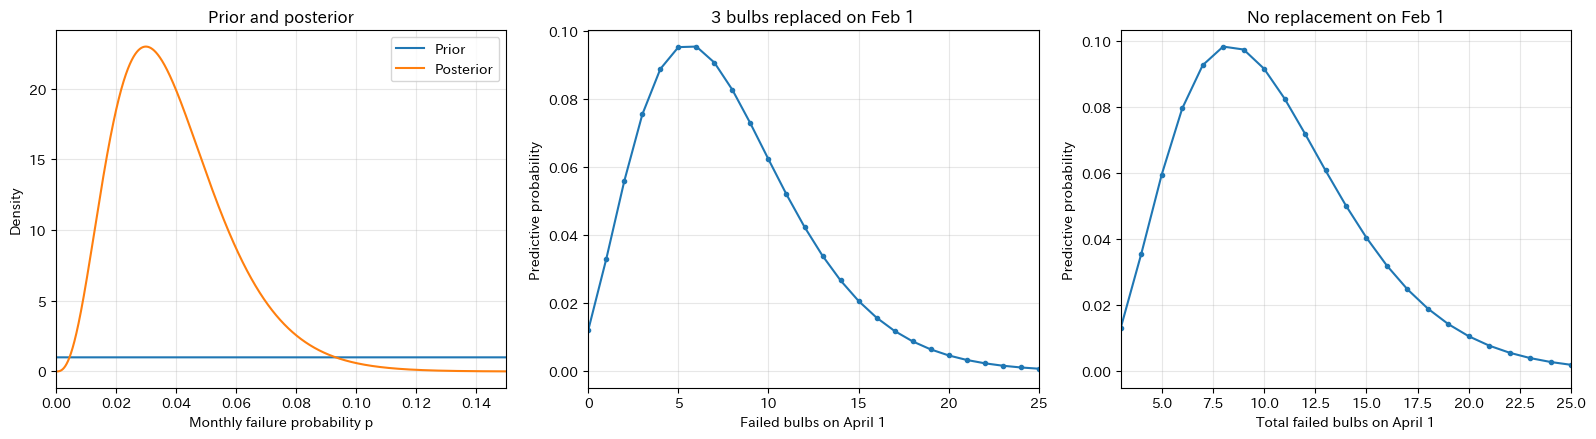

In [249]:

import numpy as np
import matplotlib.pyplot as plt
from math import lgamma

# ============================================================
# 1. 2月1日の観測
# ============================================================
n_bulbs = 100
observed_failed = 3
observed_working = 97

# ============================================================
# 2. 事前分布：故障確率 p は一様分布
# ============================================================
p = np.linspace(0.00001, 0.99999, 50001)
prior = np.ones_like(p)
prior /= prior.sum()

# ============================================================
# 3. 尤度と事後分布
# ============================================================
log_likelihood = (
    observed_failed * np.log(p)
    + observed_working * np.log1p(-p)
)
likelihood = np.exp(log_likelihood - log_likelihood.max())

posterior = prior * likelihood
posterior /= posterior.sum()

# ============================================================
# 4. 4月1日の故障数の予測分布
# ============================================================
def predict_failures(n, p, posterior):
    # 2か月間に故障する確率
    q = 1 - (1 - p)**2

    k = np.arange(n + 1)
    log_comb = np.array([
        lgamma(n + 1) - lgamma(int(x) + 1)
        - lgamma(n - int(x) + 1)
        for x in k
    ])

    # 各 p における二項分布
    log_pmf = (
        log_comb[:, None]
        + k[:, None] * np.log(q)[None, :]
        + (n - k)[:, None] * np.log1p(-q)[None, :]
    )
    conditional_pmf = np.exp(log_pmf)

    # p の事後分布で平均する
    predictive = conditional_pmf @ posterior
    predictive /= predictive.sum()

    return k, predictive

# ケースA：2月1日に3個を交換した
k_replaced, pred_replaced = predict_failures(
    100, p, posterior
)

# ケースB：2月1日に交換しなかった
# すでに切れている3個 + 残り97個の今後の故障
k_remaining, pred_remaining = predict_failures(
    97, p, posterior
)
total_failed = k_remaining + 3

# ============================================================
# 5. 数値を確認
# ============================================================
print("事後分布の平均故障確率（1か月）:",
      np.sum(p * posterior).round(4))

print("2月1日に交換した場合の4月1日の期待故障数:",
      np.sum(k_replaced * pred_replaced).round(2))

print("交換しなかった場合の4月1日の期待故障数:",
      np.sum(total_failed * pred_remaining).round(2))

# ============================================================
# 6. グラフ
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 事前分布と事後分布
axes[0].plot(p, prior / (p[1] - p[0]), label="Prior")
axes[0].plot(p, posterior / (p[1] - p[0]), label="Posterior")
axes[0].set_xlim(0, 0.15)
axes[0].set_xlabel("Monthly failure probability p")
axes[0].set_ylabel("Density")
axes[0].set_title("Prior and posterior")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ケースA
axes[1].plot(k_replaced, pred_replaced, marker="o", markersize=3)
axes[1].set_xlabel("Failed bulbs on April 1")
axes[1].set_ylabel("Predictive probability")
axes[1].set_title("3 bulbs replaced on Feb 1")
axes[1].set_xlim(0, 25)
axes[1].grid(alpha=0.3)

# ケースB
axes[2].plot(total_failed, pred_remaining,
             marker="o", markersize=3)
axes[2].set_xlabel("Total failed bulbs on April 1")
axes[2].set_ylabel("Predictive probability")
axes[2].set_title("No replacement on Feb 1")
axes[2].set_xlim(3, 25)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

形状パラメータ k の事後平均: 3.31
寿命中央値 m の事後平均: 2.89 か月
4月1日の期待故障数: 58.2 個
予測分布の中央値: 54 個
中央95%の予測範囲: 24～98 個


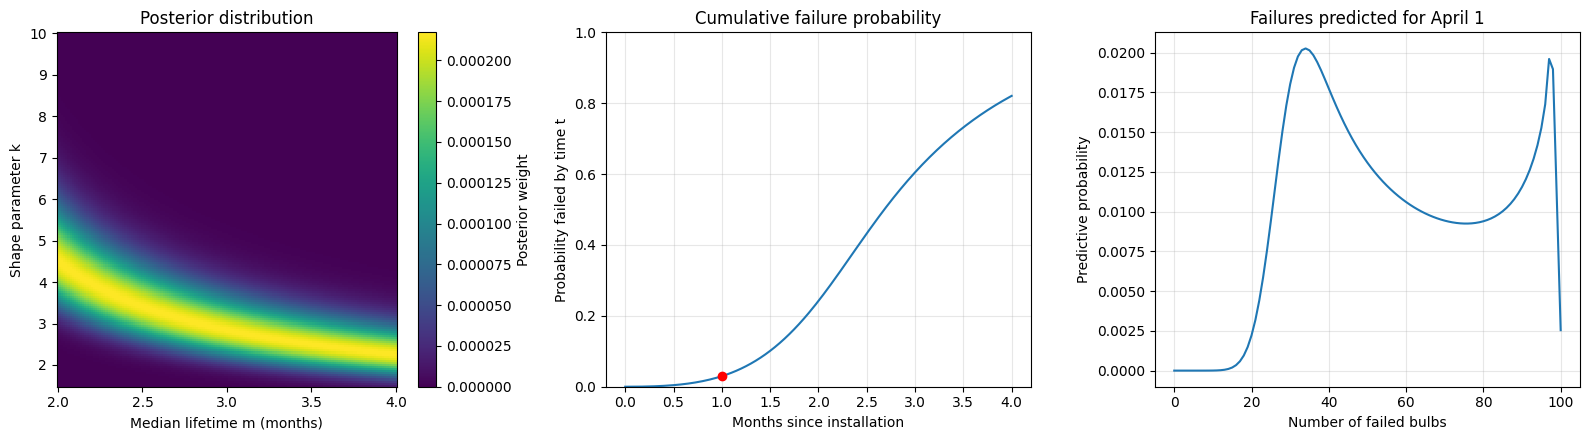

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from math import lgamma

# ============================================================
# 1. 観測データ
# ============================================================
n_bulbs = 100
failed_feb = 3
survived_feb = 97

# ============================================================
# 2. ワイブル分布のパラメータ候補
# ============================================================
# k : 形状パラメータ
# m : 寿命の中央値（月）
#
# 学習用の仮定：
# k は 1.5～10、寿命の中央値 m は 2～4か月
#
# k > 1 とすることで、年齢とともに故障率が
# 上昇するワイブルモデルを考える。

k_values = np.linspace(1.5, 10, 171)
m_values = np.linspace(2, 4, 161)

K, M = np.meshgrid(k_values, m_values, indexing="ij")

# ワイブル分布の尺度パラメータ eta
# m = eta * (ln 2)**(1/k) から求める
eta = M / (np.log(2) ** (1 / K))

# ============================================================
# 3. 故障確率と生存確率
# ============================================================
def failure_prob(t, K, eta):
    """取り付け後 t か月までに故障する確率"""
    return 1 - np.exp(-((t / eta) ** K))

def survival_prob(t, K, eta):
    """取り付け後 t か月時点で生存している確率"""
    return np.exp(-((t / eta) ** K))

# 1か月以内に故障する確率
F1 = failure_prob(1, K, eta)
S1 = survival_prob(1, K, eta)

# ============================================================
# 4. 事前分布
# ============================================================
# k と m の候補を、学習用に一様な重みで扱う
prior = np.ones_like(K)
prior = prior / prior.sum()

# ============================================================
# 5. 尤度
# ============================================================
# 100個中、1か月以内に3個故障し、97個が生存
#
# 尤度 ∝ F1**3 * S1**97
# 二項係数は、すべての候補で共通なので省略

log_likelihood = (
    failed_feb * np.log(F1)
    + survived_feb * np.log(S1)
)

likelihood = np.exp(
    log_likelihood - np.max(log_likelihood)
)

# ============================================================
# 6. 事後分布
# ============================================================
posterior = prior * likelihood
posterior = posterior / posterior.sum()

# パラメータの事後平均
mean_k = np.sum(K * posterior)
mean_m = np.sum(M * posterior)

print(f"形状パラメータ k の事後平均: {mean_k:.2f}")
print(f"寿命中央値 m の事後平均: {mean_m:.2f} か月")

# ============================================================
# 7. 4月1日の故障数を予測
# ============================================================
# 2月1日に交換した3個：
# 新品から2か月間の故障確率 F(2)
p_new = failure_prob(2, K, eta)

# 1月1日から使っている97個：
# 1か月生存したという条件のもとで、
# 3か月目までに故障する条件付き確率
S3 = survival_prob(3, K, eta)
p_old = 1 - S3 / S1

# 二項分布の確率を計算する関数
def binomial_pmf(n, p):
    """成功数 0～n の二項分布の確率"""
    p = float(np.clip(p, 0, 1))
    k = np.arange(n + 1)

    if p == 0:
        result = np.zeros(n + 1)
        result[0] = 1
        return result

    if p == 1:
        result = np.zeros(n + 1)
        result[n] = 1
        return result

    log_comb = np.array([
        lgamma(n + 1)
        - lgamma(int(x) + 1)
        - lgamma(n - int(x) + 1)
        for x in k
    ])

    log_pmf = (
        log_comb
        + k * np.log(p)
        + (n - k) * np.log1p(-p)
    )

    result = np.exp(log_pmf)
    return result / result.sum()

# 予測分布：
# 97個の継続使用電球の故障数と、
# 3個の交換電球の故障数を合算する
predictive = np.zeros(101)

for i in range(len(k_values)):
    for j in range(len(m_values)):
        weight = posterior[i, j]

        # ごく小さい重みは計算を省略
        if weight < 1e-12:
            continue

        old_pmf = binomial_pmf(97, p_old[i, j])
        new_pmf = binomial_pmf(3, p_new[i, j])

        combined = np.convolve(old_pmf, new_pmf)
        predictive += weight * combined

predictive /= predictive.sum()

numbers = np.arange(101)
expected_failures = np.sum(numbers * predictive)
median_failures = numbers[
    np.searchsorted(np.cumsum(predictive), 0.5)
]
lower_95 = numbers[
    np.searchsorted(np.cumsum(predictive), 0.025)
]
upper_95 = numbers[
    np.searchsorted(np.cumsum(predictive), 0.975)
]

print(f"4月1日の期待故障数: {expected_failures:.1f} 個")
print(f"予測分布の中央値: {median_failures} 個")
print(f"中央95%の予測範囲: {lower_95}～{upper_95} 個")

# ============================================================
# 8. グラフ
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# A. 事後分布：k と寿命中央値 m の組み合わせ
mesh = axes[0].pcolormesh(
    m_values, k_values, posterior,
    shading="auto"
)
axes[0].set_xlabel("Median lifetime m (months)")
axes[0].set_ylabel("Shape parameter k")
axes[0].set_title("Posterior distribution")
fig.colorbar(mesh, ax=axes[0], label="Posterior weight")

# B. 事後分布を使った、経過月数ごとの故障確率
months = np.linspace(0, 4, 161)
mean_F = np.array([
    np.sum(failure_prob(t, K, eta) * posterior)
    for t in months
])
axes[1].plot(months, mean_F)
axes[1].scatter([1], [np.sum(F1 * posterior)],
                       color="red", zorder=3)
axes[1].set_xlabel("Months since installation")
axes[1].set_ylabel("Probability failed by time t")
axes[1].set_title("Cumulative failure probability")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

# C. 4月1日の故障数の予測分布
axes[2].plot(numbers, predictive)
axes[2].set_xlabel("Number of failed bulbs")
axes[2].set_ylabel("Predictive probability")
axes[2].set_title("Failures predicted for April 1")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()
